# Noria · 06 — Age in the client model (experiment E15)

Pre-registered in `docs/experiments.md` (commit "Pre-register E15") as a **measurement to report**, without a decision rule:
the decision to keep `AGE_YEARS` in the client model was taken before this run (see the brief's Decision log).

Current client model (7 features) vs the same without `AGE_YEARS` (6 features): same tuned parameters (E13),
same Platt calibration fitted on out-of-fold train predictions (E8), same thresholds (E14). Validation set only;
**the test set stays locked**. Logic in `src/experiments_s5.py` (`run_e15`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, analysis, experiments_s5 as s5

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

In [2]:
try:
    data.load_split("test")
except data.TestSetLockedError as error:
    print("As expected:", error)
train, val = data.load_train_val()
models = s5.final_models(train, val)
print("CLIENT_FEATURES (unchanged):", config.CLIENT_FEATURES)

As expected: The test set is locked until the final evaluation. Use load_split('test', final=True) only for the final results.


CLIENT_FEATURES (unchanged): ['AGE_YEARS', 'NAME_FAMILY_STATUS', 'CNT_CHILDREN', 'NAME_INCOME_TYPE', 'EMPLOYMENT_YEARS', 'IS_PENSIONER', 'CREDIT_INCOME_RATIO']


In [3]:
e15, p_cal = s5.run_e15(train, val, models)
print(f"Trees: with age {e15['n_trees_with_age']} · without age {e15['n_trees_without_age']}")
rows = []
for g, r in e15["auc"].items():
    d = r["with_minus_without"]
    rows.append({"group": g, "rows": r["rows"], "defaults": r["defaults"],
                 "AUC with age [95% CI]": f"{r['with_age']['roc_auc']:.4f} [{r['with_age']['ci_low']:.4f}, {r['with_age']['ci_high']:.4f}]",
                 "AUC without age [95% CI]": f"{r['without_age']['roc_auc']:.4f} [{r['without_age']['ci_low']:.4f}, {r['without_age']['ci_high']:.4f}]",
                 "with - without [paired 95% CI]": f"{d['auc_diff']:+.4f} [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]"})
pd.DataFrame(rows).set_index("group")

Trees: with age 218 · without age 192


,rows,defaults,AUC with age [95% CI],AUC without age [95% CI],with - without [paired 95% CI]
group,,,,,
all,41735,3483,"0.6207 [0.6107, 0.6307]","0.6141 [0.6039, 0.6243]","+0.0065 [+0.0035, +0.0097]"
20-35,11153,1273,"0.5921 [0.5752, 0.6091]","0.5903 [0.5735, 0.6071]","+0.0018 [-0.0032, +0.0070]"
Commercial associate,9642,739,"0.5891 [0.5687, 0.6093]","0.5818 [0.5609, 0.6027]","+0.0073 [-0.0031, +0.0171]"


In [4]:
for variant in ["with_age", "without_age"]:
    print(f"=== {variant}: overall classes")
    display(pd.DataFrame(e15["classes_overall"][variant]).set_index("class")[["label", "clients", "share", "default_rate"]]
              .assign(share=lambda t: (t["share"] * 100).round(2), default_rate=lambda t: (t["default_rate"] * 100).round(2))
              .rename(columns={"share": "share (%)", "default_rate": "actual default rate (%)"}))

=== with_age: overall classes


,label,clients,share (%),actual default rate (%)
class,,,,
low,favorable,4757,11.40,4.50
medium,to strengthen,30523,73.14,7.72
high,fragile,6455,15.47,14.16


=== without_age: overall classes


,label,clients,share (%),actual default rate (%)
class,,,,
low,favorable,4117,9.86,4.52
medium,to strengthen,31494,75.46,7.70
high,fragile,6124,14.67,14.22


In [5]:
by_age = pd.concat({v: pd.DataFrame(rows) for v, rows in e15["classes_by_age"].items()}, names=["variant"]).reset_index(level=0)
share = by_age.pivot_table(index=["variant", "age_group"], columns="category", values="share").mul(100).round(2)
rate = by_age.pivot_table(index=["variant", "age_group"], columns="category", values="default_rate").mul(100).round(2)
cols = ["favorable", "to strengthen", "fragile"]
print("Share of clients per category (%), by age group")
display(share[cols])
print("Actual default rate per category (%), by age group")
display(rate[cols])

Share of clients per category (%), by age group


category               favorable  to strengthen  fragile
variant     age_group                                   
with_age    20-25           0.00          40.29    59.71
            25-35           0.42          61.74    37.84
            35-45           6.20          79.33    14.47
            45-55          14.70          82.48     2.82
            55-70          27.29          72.71     0.00
without_age 20-25           0.00          55.77    44.23
            25-35           1.30          74.27    24.43
            35-45           7.16          76.94    15.90
            45-55          13.19          75.51    11.30
            55-70          20.01          77.69     2.30

Actual default rate per category (%), by age group


category               favorable  to strengthen  fragile
variant     age_group                                   
with_age    20-25            NaN           9.78    15.40
            25-35           0.00           9.25    14.42
            35-45           5.75           8.05    12.97
            45-55           5.48           7.71    14.07
            55-70           3.70           5.77      NaN
without_age 20-25            NaN          10.47    16.50
            25-35           2.36           9.66    16.23
            35-45           5.70           8.03    12.79
            45-55           5.15           7.34    11.85
            55-70           3.73           5.45     9.59

Figure saved: reports/figures/18_e15_client_categories_by_age.png


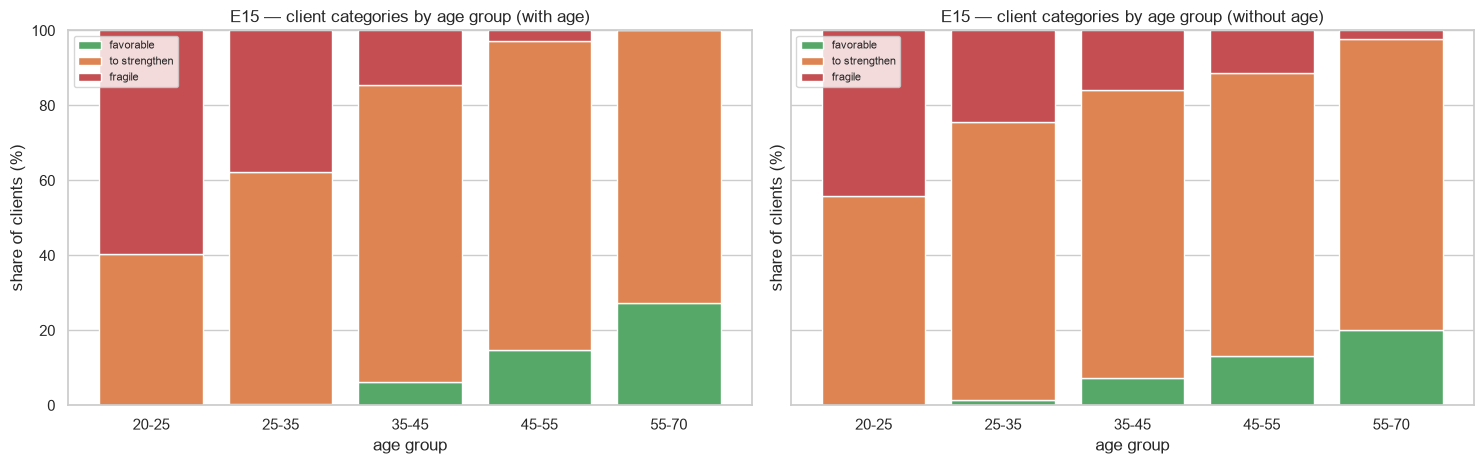

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
colors = {"favorable": "#55A868", "to strengthen": "#DD8452", "fragile": "#C44E52"}
for ax, variant in zip(axes, ["with_age", "without_age"]):
    t = share.loc[variant][cols]
    bottom = np.zeros(len(t))
    for c in cols:
        ax.bar(t.index, t[c], bottom=bottom, color=colors[c], label=c)
        bottom += t[c].to_numpy()
    ax.set_title(f"E15 — client categories by age group ({variant.replace('_', ' ')})")
    ax.set_xlabel("age group"); ax.set_ylabel("share of clients (%)")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
save(fig, "18_e15_client_categories_by_age.png")
plt.show()

## Findings

Validation set (41,735 clients). Measurement to report: `AGE_YEARS` stays in `CLIENT_FEATURES` (decision taken before this run).

1. **Overall AUC**: with age **0.6207** [0.6107, 0.6307] (218 trees) vs without age **0.6141** [0.6039, 0.6243] (192 trees). Removing age costs **−0.0065** AUC: the paired difference with − without is +0.0065 [+0.0035, +0.0097], above 0.
2. **Target groups**: the difference is not significant.
   - 20-35 year-olds: 0.5921 with age vs 0.5903 without, +0.0018 [−0.0032, +0.0070].
   - `Commercial associate`: 0.5891 vs 0.5818, +0.0073 [−0.0031, +0.0171].

   Both stay below 0.60 with or without age.
3. **Overall categories**: with age, favorable / to strengthen / fragile = 11.40% / 73.14% / 15.47% (actual default rates 4.50% / 7.72% / 14.16%). Without age: 9.86% / 75.46% / 14.67% (4.52% / 7.70% / 14.22%).
4. **Categories by age group**: removing age does **not** make young applicants "favorable".
   - 20-25: 0.00% favorable in both versions; fragile 59.71% → 44.23%.
   - 25-35: favorable 0.42% → 1.30%; fragile 37.84% → 24.43%.
   - 55-70: favorable 27.29% → 20.01%; fragile 0.00% → 2.30%.

   Employment length, which is strongly linked to age, keeps most of the age gradient.
5. **The categories stay meaningful within each age group** (with age). Among 20-25 year-olds the actual default rate is 9.78% in "to strengthen" vs 15.40% in "fragile"; among 25-35 it is 9.25% vs 14.42%.